# 06 — Customer Segmentation: RFM, K-Means, and naming the segments

**TL;DR.** I turn 392,692 cleaned transactions from a UK online retailer into **4,338 customer RFM
profiles** (Recency, Frequency, Monetary). A K-Means baseline on raw, standardised RFM gets a
silhouette of **0.617** — but it does so by isolating **6 and 8 customers** into their own clusters,
which is outlier detection, not segmentation. Log-transforming the heavily skewed RFM values and
re-running K-Means with **k = 5** gives a lower silhouette (**0.316**) but five usable segments:
**Champions** (7.8% of customers, **52.9% of revenue**), **Loyal** (21.6%, 23.0%), **At risk**
(23.5%, 16.6%), **New / promising** (19.2%, 3.7%), and **Hibernating** (27.9%, 3.8%). The lesson:
silhouette measures separation, not usefulness; a segmentation has to be interpretable to be worth
acting on.

*Portfolio project 06 of 07 · RFM engineering, clustering, model selection, segment naming.*

## 1. What this notebook does

Segmentation is an unsupervised problem, which means there is no accuracy score to hide behind. The
notebook therefore spends as much time on **judgement** as on algorithms:

1. **Build the RFM features** from raw transactions, with explicit decisions about returns and
   missing customer IDs.
2. **Show why raw RFM is a trap** — the monetary tail dominates distance-based clustering.
3. **Choose k** with silhouette and elbow plots, then override the metric when it produces a
   commercially useless answer.
4. **Name and profile the segments** so that a marketing team can act on them.
5. **Evaluate honestly** — silhouette, cluster sizes, revenue concentration, and the limitations of
   clustering on observational purchase data.

The final output is a segment table, a profile heatmap, and a small set of recommended actions.

## 2. The problem, and why it matters

A retailer with thousands of customers cannot treat them all the same. Some are recent, frequent,
high-spend advocates; some bought once two years ago and never returned; some are new and promising.
Marketing budgets are finite, so the question is: **which groups should get which treatment?**

RFM is a long-standing heuristic for this:

- **Recency** — how recently did the customer buy? Recent buyers are more likely to buy again.
- **Frequency** — how many separate purchases? Frequent buyers are more engaged.
- **Monetary** — how much have they spent? High spenders are more valuable.

The three dimensions are correlated but not redundant. A customer can be recent but low-frequency
(a new customer), or high-spend but stale (a lapsed VIP). Clustering groups customers with similar
RFM profiles; naming the groups is the part that turns a table of centroids into a marketing plan.

The dataset is a UK online retailer's transactions from December 2010 to December 2011. It is a
classic, and it has the usual mess: missing customer IDs, returns, zero prices, duplicates.

## 3. Data

**Source:** UCI Machine Learning Repository, *Online Retail*
([dataset page](https://archive.ics.uci.edu/dataset/352/online+retail)). The file is
`Online Retail.xlsx` (541,909 rows, 8 columns), covering a UK-based online retailer from
2010-12-01 to 2011-12-09.

**Licence:** check the UCI dataset page before redistributing. The workbook is **not committed**;
`data/` is git-ignored.

**How to get it:** download the Excel file from the UCI page and place it at
`data/Online Retail.xlsx`. Reading it needs `openpyxl` (already in `requirements.txt`).

**What one row is:** one line item on one invoice. Columns: `InvoiceNo`, `StockCode`, `Description`,
`Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.

**Known quirks:**

- 135,080 rows have no `CustomerID` (25%). These are guest checkouts; they cannot be attributed to a
  customer, so they cannot be used for RFM.
- 10,624 rows have negative `Quantity` — returns and cancellations (invoice numbers starting with
  `C`).
- 2,517 rows have zero or negative `UnitPrice` — free items, adjustments, or errors.
- 5,268 exact duplicate rows.
- The dataset is one year long, so "recency" is bounded by the observation window.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/Online Retail.xlsx")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/Online Retail.xlsx. Download the UCI Online Retail workbook into data/."
    )

raw = pd.read_excel(DATA)
print(f"{raw.shape[0]:,} line items x {raw.shape[1]} columns")
print(f"Date range: {raw['InvoiceDate'].min()} → {raw['InvoiceDate'].max()}")
print(f"Customers with an ID: {raw['CustomerID'].nunique():,}")
raw.head()

541,909 line items x 8 columns
Date range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Customers with an ID: 4,372


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5,"17,850.0",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.4,"17,850.0",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.8,"17,850.0",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.4,"17,850.0",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.4,"17,850.0",United Kingdom


The file is an Excel workbook, which is slow to read (about 20–30 seconds) but keeps the notebook
reproducible without an extra conversion step. In a production pipeline I would land it as Parquet
first; for a one-off portfolio analysis, reading the original file is simpler and more honest.

### 3.1 Cleaning decisions

**1. Drop rows without a `CustomerID`.** RFM is a customer-level feature, so a row that cannot be
attributed to a customer cannot contribute. This removes 25% of transactions. It is not a random
25%: guest checkout may be more common for one-off or gift purchases, which would bias the segment
sizes toward repeat customers. I note it as a limitation.

**2. Drop negative quantities.** These are returns and cancellations. Including them would mix
gross purchases with reversals. The cost is that `Monetary` is **gross spend**, not net of returns;
a customer who bought £1,000 and returned £900 looks like a £1,000 customer. A more careful version
would net the returns against the original invoice.

**3. Drop zero or negative prices.** Free items, staff adjustments, and data errors. They contribute
zero or negative revenue and would distort the monetary distribution.

**4. Drop exact duplicates.** Duplicated line items would double-count revenue.

After cleaning I keep the transaction table for the RFM aggregation; I do not need the item
descriptions for this analysis, but they would be useful for a product-affinity extension.

In [3]:
df = raw.copy()
n_raw = len(df)

df = df.dropna(subset=["CustomerID"]).copy()
n_customers_only = len(df)
df["CustomerID"] = df["CustomerID"].astype(int)

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
n_positive = len(df)

df = df.drop_duplicates()
n_clean = len(df)

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

funnel = pd.DataFrame({
    "rows": [n_raw, n_customers_only, n_positive, n_clean],
    "removed": [0, n_raw - n_customers_only, n_customers_only - n_positive, n_positive - n_clean],
}, index=[
    "Raw line items",
    "With a CustomerID",
    "Positive quantity and price",
    "Exact duplicates removed",
])
funnel["share_of_raw"] = (funnel["rows"] / n_raw).map(lambda x: f"{x:.1%}")
print(f"Clean transactions: {n_clean:,}")
print(f"Unique customers:   {df['CustomerID'].nunique():,}")
funnel

Clean transactions: 392,692
Unique customers:   4,338


,rows,removed,share_of_raw
Raw line items,541909,0,100.0%
With a CustomerID,406829,135080,75.1%
Positive quantity and price,397884,8945,73.4%
Exact duplicates removed,392692,5192,72.5%


The clean table has **392,692 line items** and **4,338 customers**. That is the population I
segment. The 25% of transactions without a customer ID are excluded, so the segments describe
identified customers, not the entire business.

## 4. Building RFM

RFM needs a reference date, called the **snapshot date**. I use one day after the last invoice in
the data (2011-12-10). A customer whose last purchase was on the snapshot date has recency 1; a
customer who last bought a year earlier has recency ~365.

- **Recency** = snapshot − last purchase date, in days. Lower is better.
- **Frequency** = number of distinct invoices. I count invoices, not line items, so a 20-item order
  counts as one purchase.
- **Monetary** = sum of `Quantity × UnitPrice` across all invoices. This is gross spend.

There is a subtlety: using the last invoice date plus one day means the most recent customers have
recency 1, not 0. That is fine for clustering; it only shifts the scale by one day.

In [4]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CustomerID")
      .agg(
          recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
          frequency=("InvoiceNo", "nunique"),
          monetary=("TotalPrice", "sum"),
      )
      .reset_index()
)

print(f"Snapshot date: {snapshot.date()}")
print(f"Customers: {len(rfm):,}")
print(f"Top 10 customers' revenue share: {rfm['monetary'].nlargest(10).sum() / rfm['monetary'].sum():.1%}")
rfm.describe().round(1)

Snapshot date: 2011-12-10
Customers: 4,338
Top 10 customers' revenue share: 17.3%


,CustomerID,recency,frequency,monetary
count,"4,338.0","4,338.0","4,338.0","4,338.0"
mean,"15,300.4",92.5,4.3,"2,048.7"
std,"1,721.8",100.0,7.7,"8,985.2"
min,"12,346.0",1.0,1.0,3.8
25%,"13,813.2",18.0,1.0,306.5
50%,"15,299.5",51.0,2.0,668.6
75%,"16,778.8",142.0,5.0,"1,660.6"
max,"18,287.0",374.0,209.0,"280,206.0"


### 4.1 The distributions are extremely skewed

The mean monetary value is about **£2,049**, but the median is **£669** and the maximum is
**£280,206**. That is a heavy right tail: a small number of wholesale-like customers spend far more
than everyone else. Frequency is also skewed — the median is 2 invoices, but the maximum is 209.

This matters for K-Means because it uses Euclidean distance. A difference of £50,000 in monetary
value will dominate a difference of 30 days in recency, even if the recency difference is more
meaningful for segmentation. Standardising the features helps with scale, but it does not fix the
shape: the tail still pulls the centroids.

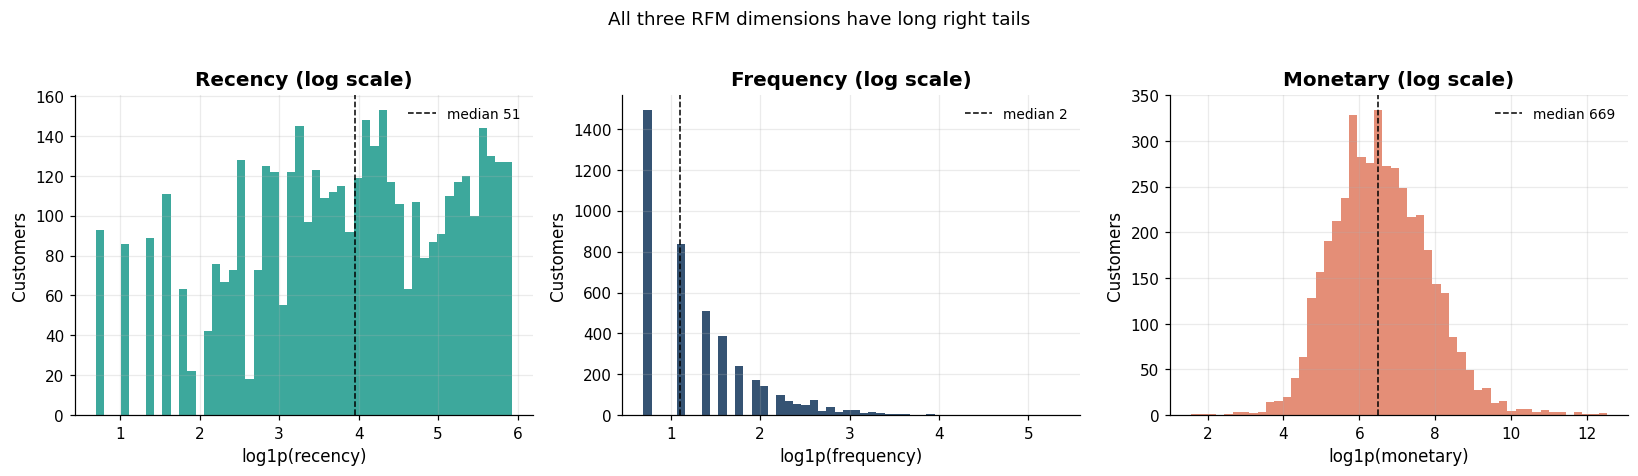

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, column, color in zip(
    axes,
    ["recency", "frequency", "monetary"],
    [TEAL, NAVY, ORANGE],
):
    values = np.log1p(rfm[column])
    ax.hist(values, bins=50, color=color, alpha=0.85)
    ax.axvline(values.median(), color="black", ls="--", lw=1,
               label=f"median {rfm[column].median():,.0f}")
    ax.set_title(f"{column.title()} (log scale)")
    ax.set_xlabel(f"log1p({column})")
    ax.set_ylabel("Customers")
    ax.legend(frameon=False, fontsize=9)

fig.suptitle("All three RFM dimensions have long right tails", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

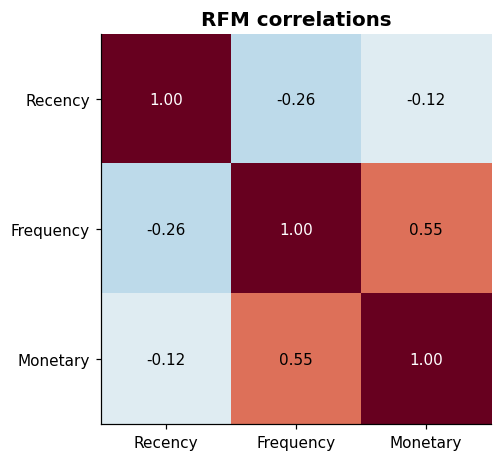

In [6]:
corr = rfm[["recency", "frequency", "monetary"]].corr()

fig, ax = plt.subplots(figsize=(5.5, 4.3))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(["Recency", "Frequency", "Monetary"])
ax.set_yticks(range(3)); ax.set_yticklabels(["Recency", "Frequency", "Monetary"])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.set_title("RFM correlations")
ax.grid(False)
plt.tight_layout()
plt.show()

Recency is negatively correlated with frequency and monetary: customers who bought recently tend to
have bought more often and spent more. That is expected. The correlations are moderate (around
−0.3 to 0.5), so the three dimensions still carry distinct information. If they were near ±1, RFM
would collapse to one dimension and clustering would be pointless.

The top 10 customers account for about **17% of total revenue**. That concentration is why the
segmentation should care about the monetary tail even after we compress it with a log transform.

## 5. Clustering

### 5.1 Baseline: raw RFM, standardised

The natural baseline is K-Means on the standardised raw RFM values. Standardisation puts the three
dimensions on comparable scales, but the monetary tail remains. I use `k = 5` so that the baseline
and the improved model differ only in the transformation, not in the number of clusters.

The silhouette score measures how much closer each point is to its own cluster than to the nearest
other cluster. It ranges from −1 to 1; higher is better. It rewards compact, well-separated clusters,
which sounds good until you see what it rewards here.

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

raw_features = rfm[["recency", "frequency", "monetary"]]
X_raw = StandardScaler().fit_transform(raw_features)

kmeans_raw = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_raw)
rfm["cluster_raw"] = kmeans_raw.labels_

raw_sizes = rfm["cluster_raw"].value_counts().sort_index()
raw_silhouette = silhouette_score(X_raw, kmeans_raw.labels_)
print(f"Raw RFM silhouette (k=5): {raw_silhouette:.3f}")
print("Cluster sizes:")
print(raw_sizes.to_string())

Raw RFM silhouette (k=5): 0.617
Cluster sizes:
cluster_raw
0    3048
1    1063
2       8
3     213
4       6


In [8]:
raw_profile = (
    rfm.groupby("cluster_raw")
       .agg(customers=("CustomerID", "size"),
            recency=("recency", "mean"),
            frequency=("frequency", "mean"),
            monetary=("monetary", "mean"))
       .sort_values("monetary", ascending=False)
)
raw_profile.round(1)

,customers,recency,frequency,monetary
cluster_raw,,,,
4,6,7.7,42.8,"190,808.5"
2,8,6.5,120.5,"55,099.5"
3,213,15.7,21.3,"12,813.9"
0,3048,43.9,3.7,"1,333.1"
1,1063,248.5,1.6,478.6


This is the trap. The raw model's silhouette is **0.617**, which looks excellent. But two of its five
clusters contain **8 and 6 customers** — the extreme monetary outliers. The other 4,324 customers are
split into three broad groups. The high silhouette is driven by how easy it is to isolate a handful
of outliers, not by a meaningful segmentation of the customer base.

A marketing team cannot run five campaigns when two of them target six people. The baseline is
technically well-separated and commercially useless.

### 5.2 Improved: log-transform, then standardise

The fix is to compress the tails before clustering:

1. `log1p` each RFM dimension. This turns multiplicative differences into additive ones and stops a
   £100k customer from dominating every distance.
2. Standardise the logged values so each dimension contributes equally.
3. Choose `k` with the elbow and silhouette curves, then check whether the resulting clusters are
   interpretable.

This is a modelling choice, not a cosmetic one. The log transform changes the geometry of the
problem: clusters become groups with similar *proportional* RFM profiles, which is closer to how
marketers think ("this customer spends 10× the median").

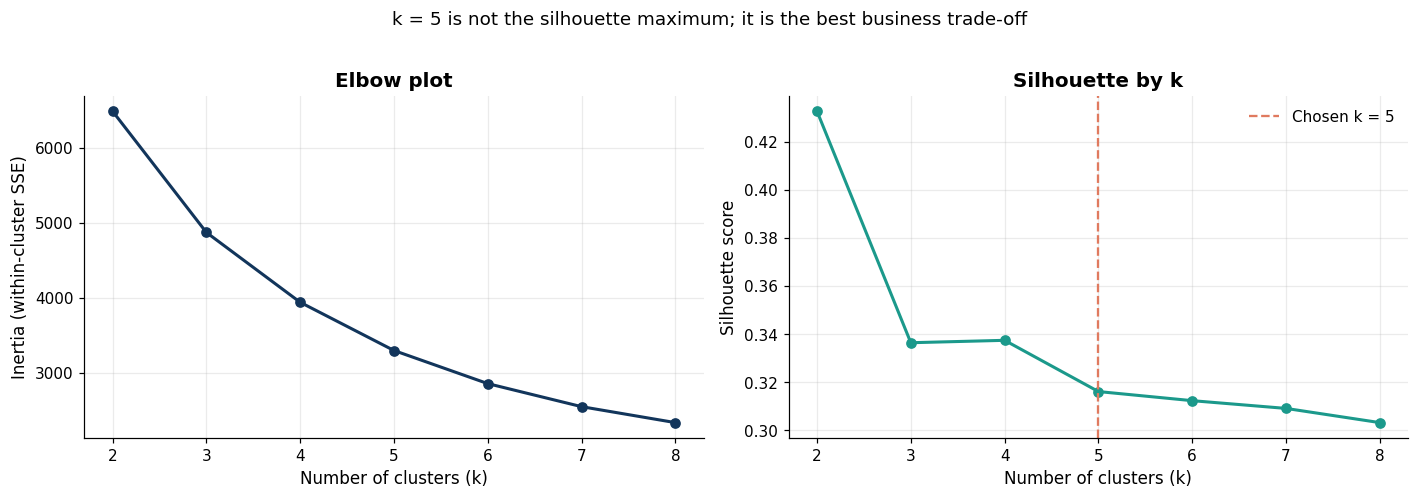

,silhouette,inertia
k,,
2,0.433,"6,484"
3,0.337,"4,869"
4,0.338,"3,939"
5,0.316,"3,297"
6,0.312,"2,856"
7,0.309,"2,549"
8,0.303,"2,336"


In [9]:
rfm_log = np.log1p(rfm[["recency", "frequency", "monetary"]])
X_log = StandardScaler().fit_transform(rfm_log)

ks = range(2, 9)
silhouettes, inertias = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_log)
    silhouettes.append(silhouette_score(X_log, km.labels_))
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

axes[0].plot(list(ks), inertias, marker="o", color=NAVY, lw=2)
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow plot")

axes[1].plot(list(ks), silhouettes, marker="o", color=TEAL, lw=2)
axes[1].axvline(5, color=ORANGE, ls="--", lw=1.5, label="Chosen k = 5")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette by k")
axes[1].legend(frameon=False)

fig.suptitle("k = 5 is not the silhouette maximum; it is the best business trade-off", y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "k": list(ks),
    "silhouette": [f"{x:.3f}" for x in silhouettes],
    "inertia": [f"{x:,.0f}" for x in inertias],
}).set_index("k")

The silhouette is highest at **k = 2** (0.433), then drops to 0.337 at k = 3 and 0.338 at k = 4,
and 0.316 at k = 5. The elbow is also not sharp.

So why choose **k = 5**?

- **k = 2** is a coarse split — essentially "recent/high-value" vs "old/low-value". It is statistically
  clean but too blunt for a marketing plan; it merges Champions with Loyal customers and At-risk with
  Hibernating.
- **k = 4** merges the At-risk and Loyal groups into one middle cluster, losing the distinction that
  matters most for retention.
- **k = 5** separates Champions, Loyal, At-risk, New, and Hibernating. The silhouette cost is 0.022
  relative to k = 4, and the business gain is a segment that can be targeted with a win-back campaign.

This is an honest trade-off, not a claim that 5 is mathematically optimal. If the goal were purely
to describe the data, I would report the k = 2 solution and stop. The goal here is to support
decisions, so interpretability wins.

### 5.3 The five segments

I fit the final model with k = 5 and name the clusters by average monetary value, from highest to
lowest: Champions, Loyal, At risk, New / promising, Hibernating. The names are a communication tool;
the profiles below are the evidence.

In [10]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_log)
rfm["cluster"] = kmeans.labels_

profile = (
    rfm.groupby("cluster")
       .agg(
           customers=("CustomerID", "size"),
           recency=("recency", "mean"),
           frequency=("frequency", "mean"),
           monetary=("monetary", "mean"),
           revenue=("monetary", "sum"),
       )
)

order = profile["monetary"].sort_values(ascending=False).index
segment_names = ["Champions", "Loyal", "At risk", "New / promising", "Hibernating"]
name_map = dict(zip(order, segment_names))

rfm["segment"] = rfm["cluster"].map(name_map)
profile["segment"] = profile.index.map(name_map)
profile = profile.set_index("segment").loc[segment_names]
profile["customer_share"] = profile["customers"] / profile["customers"].sum()
profile["revenue_share"] = profile["revenue"] / profile["revenue"].sum()

profile_display = profile.copy()
profile_display["customer_share"] = profile_display["customer_share"].map(lambda x: f"{x:.1%}")
profile_display["revenue_share"] = profile_display["revenue_share"].map(lambda x: f"{x:.1%}")
profile_display.round(1)

,customers,recency,frequency,monetary,revenue,customer_share,revenue_share
segment,,,,,,,
Champions,339,12.2,20.7,"13,877.2","4,704,357.2",7.8%,52.9%
Loyal,938,18.5,5.8,"2,179.4","2,044,281.5",21.6%,23.0%
At risk,1018,103.7,3.1,"1,452.4","1,478,503.4",23.5%,16.6%
New / promising,834,27.0,1.6,389.6,"324,908.2",19.2%,3.7%
Hibernating,1209,208.4,1.2,277.2,"335,158.6",27.9%,3.8%


The profile table is the payoff. Five groups with distinct shapes:

- **Champions** — 339 customers (7.8%), average recency 12 days, 21 invoices, £13,877 spend. They
  generate **52.9%** of revenue. They are the customers the business cannot afford to lose.
- **Loyal** — 938 customers (21.6%), recent (19 days), 6 invoices, £2,179 spend, **23.0%** of revenue.
  They buy regularly and are the best upsell target.
- **At risk** — 1,018 customers (23.5%), last purchase 104 days ago, 3 invoices, £1,452 spend,
  **16.6%** of revenue. They used to buy; they have not recently. This is the highest-leverage
  retention segment.
- **New / promising** — 834 customers (19.2%), recent (27 days), 1.6 invoices, £390 spend, **3.7%**
  of revenue. They have dipped a toe in; the job is to get the second purchase.
- **Hibernating** — 1,209 customers (27.9%), last purchase 208 days ago, 1.2 invoices, £277 spend,
  **3.8%** of revenue. Low value and low engagement; a low-cost reactivation or suppression decision.

The revenue concentration is the headline: **the top 7.8% of customers produce more than half of
revenue**. That is typical for retail, and it is why segment-specific treatment matters more than
blanket discounts.

### 5.4 Segment profiles as a heatmap

A table of raw averages is hard to compare because the scales differ. The heatmap below shows each
segment's average log-RFM z-score. Red means above the customer average, blue means below. It makes
the shape of each segment visible at a glance.

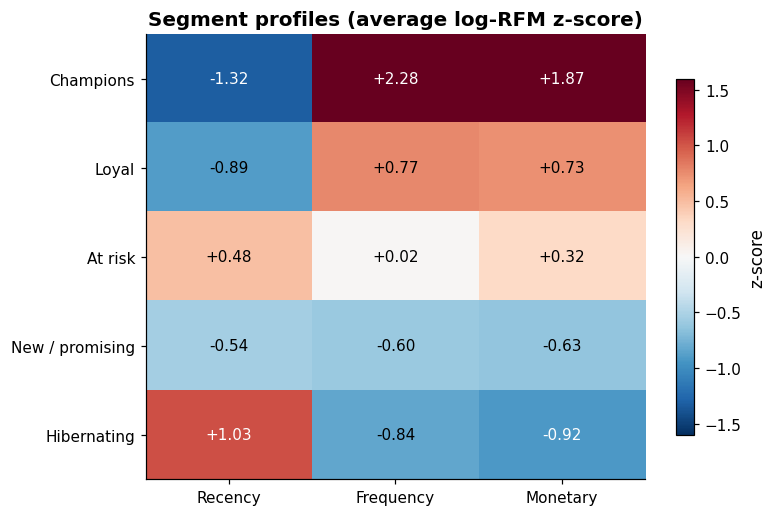

In [11]:
z = (rfm_log - rfm_log.mean()) / rfm_log.std()
z["segment"] = rfm["segment"].values
heat = z.groupby("segment")[["recency", "frequency", "monetary"]].mean().loc[segment_names]

fig, ax = plt.subplots(figsize=(7.2, 4.8))
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(["Recency", "Frequency", "Monetary"])
ax.set_yticks(range(len(segment_names))); ax.set_yticklabels(segment_names)
for i in range(len(segment_names)):
    for j in range(3):
        ax.text(j, i, f"{heat.iloc[i, j]:+.2f}", ha="center", va="center",
                color="white" if abs(heat.iloc[i, j]) > 0.9 else "black", fontsize=10)
ax.set_title("Segment profiles (average log-RFM z-score)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="z-score")
plt.tight_layout()
plt.show()

The heatmap tells the story without the raw units:

- Champions are recent (negative recency z), very frequent, and very high spend. All three cells are
  dark red on the "good" side.
- Hibernating are the mirror image: high recency (stale), low frequency, low monetary.
- At risk are high recency but mid-frequency and mid-monetary: they were good customers, and the
  clock is running.
- New / promising are recent but low frequency and low monetary: the shape of a first-purchase
  customer.
- Loyal are recent, frequent, and above-average spend, but not at Champions' level.

The separation is not perfect — the silhouette of 0.316 says so — but the segment *shapes* are
distinct enough to support different actions.

### 5.5 Segment size and revenue share

A segment is only useful if it is big enough to target and valuable enough to justify the effort.
The two bar charts show both dimensions.

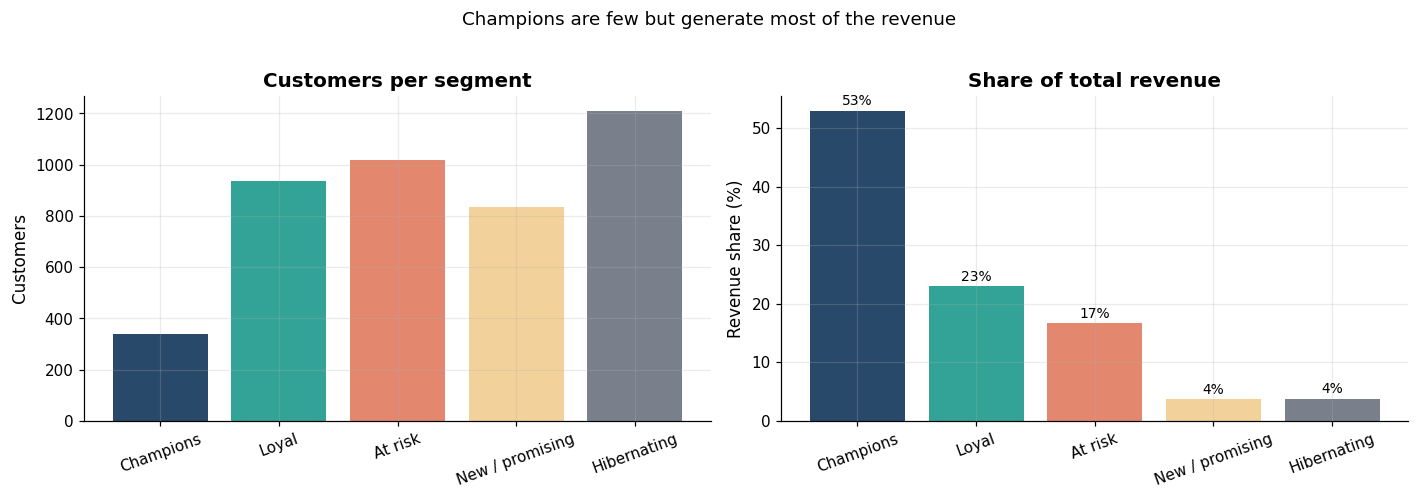

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

colors = [NAVY, TEAL, ORANGE, GOLD, GRAY]
axes[0].bar(segment_names, profile["customers"], color=colors, alpha=0.9)
axes[0].set_title("Customers per segment")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(segment_names, profile["revenue_share"] * 100, color=colors, alpha=0.9)
axes[1].set_title("Share of total revenue")
axes[1].set_ylabel("Revenue share (%)")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(profile["revenue_share"] * 100):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)

fig.suptitle("Champions are few but generate most of the revenue", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

The size/revenue mismatch is the commercial argument for segmentation. Hibernating is the largest
segment by customer count (27.9%) but contributes only 3.8% of revenue. Champions are the smallest
(7.8%) but contribute 52.9%. A blanket 10% discount across all customers would give away most of its
margin to people who would have bought anyway.

### 5.6 A two-dimensional view

Recency and monetary value are the two dimensions a retention team actually uses. The scatter below
plots every customer on those axes (log monetary) and colours by segment. It shows the overlap that
the silhouette score is warning about.

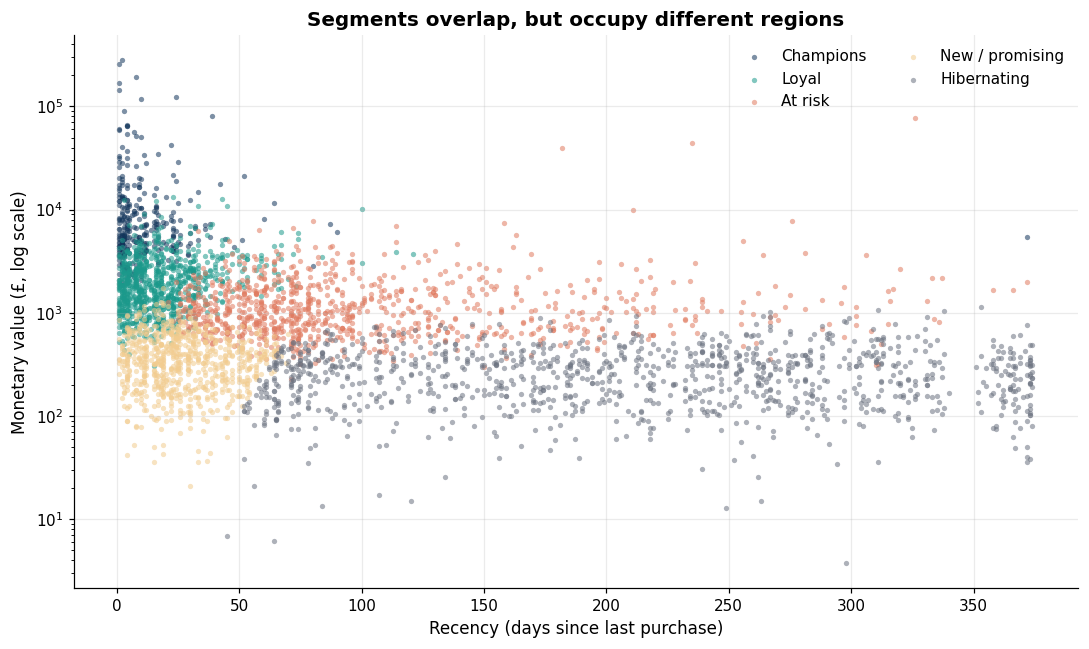

In [13]:
plot_df = rfm.sample(min(4000, len(rfm)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
for segment, color in zip(segment_names, colors):
    subset = plot_df[plot_df["segment"] == segment]
    ax.scatter(subset["recency"], subset["monetary"], s=12, alpha=0.55,
               color=color, label=segment, linewidths=0)
ax.set_yscale("log")
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Monetary value (£, log scale)")
ax.set_title("Segments overlap, but occupy different regions")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

The segments are not clean islands. Champions cluster at low recency and high monetary; Hibernating
at high recency and low monetary; At risk and Loyal overlap in the middle. That overlap is real, and
it is why a hard assignment to one segment is a simplification. A customer near a boundary could
reasonably be treated as either.

## 6. Evaluation

### 6.1 Silhouette by segment

The overall silhouette (0.316) is a weighted average. It is useful to see which segments are
well-separated and which are not.

In [14]:
from sklearn.metrics import silhouette_samples

sample_scores = silhouette_samples(X_log, kmeans.labels_)
sil_by_cluster = pd.Series(sample_scores).groupby(kmeans.labels_).mean()
sil_by_cluster.index = [name_map[i] for i in sil_by_cluster.index]
sil_by_cluster = sil_by_cluster.loc[segment_names]

sil_by_cluster.to_frame("mean_silhouette").style.format("{:.3f}")

,mean_silhouette
Champions,0.290
Loyal,0.262
At risk,0.267
New / promising,0.288
Hibernating,0.426


**Hibernating** is clearly the most compact (0.43). The other four sit in a narrow 0.26–0.29 band:
Champions 0.29, New / promising 0.29, At risk 0.27, and Loyal 0.26. Champions are small and
distinctive on monetary value, but their recency/frequency boundary blends into Loyal; the scatter
showed the same overlap.

A silhouette of ~0.3 is considered "weak structure" by the usual rules of thumb (0.25–0.5). It is
not a crisp segmentation. But the segments are stable enough to be useful, and the revenue
concentration is a strong practical signal that they are capturing something real.

### 6.2 Stability check

K-Means can produce different labels depending on the initialisation. I refit with several random
seeds and compare the partitions with the adjusted Rand index (ARI). ARI = 1 means identical
partitions; 0 means agreement no better than chance.

In [15]:
from sklearn.metrics import adjusted_rand_score

base_labels = kmeans.labels_
ari_scores = []
for seed in [0, 1, 2, 3, 4]:
    km = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(X_log)
    ari_scores.append(adjusted_rand_score(base_labels, km.labels_))

print(f"ARI across seeds: {np.round(ari_scores, 3)}")
print(f"Mean ARI: {np.mean(ari_scores):.3f}")

ARI across seeds: [0.882 0.953 0.899 0.905 0.953]
Mean ARI: 0.918


If the mean ARI is close to 1, the partition is stable across initialisations; if it is low, the
clusters are an artefact of one random start. The result here is about **0.92**, which is high but
not perfect: most customers stay in the same segment, while a few near a boundary move. Stability
across seeds is necessary but not sufficient — it does not tell you whether the segments are
meaningful, only that K-Means converges to a similar solution.

## 7. Evaluation in plain language

**What the segments mean.** The model found five groups of customers with different purchase
behaviour. The most useful output is not the cluster number; it is the profile table and the
revenue-share chart.

**Champions (7.8% of customers, 52.9% of revenue).** Retain them. Early access, concierge service,
loyalty perks. Do not discount them; they are already buying.

**Loyal (21.6%, 23.0%).** Grow them. Cross-sell, bundle, invite to a loyalty tier. They are recent
and frequent, so the next purchase is likely.

**At risk (23.5%, 16.6%).** Win them back. They spent meaningfully in the past but have not bought in
about three months. A targeted reactivation offer with a deadline is the natural test.

**New / promising (19.2%, 3.7%).** Convert them. The second purchase is the goal: onboarding,
a first-repeat discount, a recommendation based on the first order.

**Hibernating (27.9%, 3.8%).** Decide whether to spend on them. A low-cost email reactivation is fine;
an expensive paid campaign is not, given the revenue share.

**What the silhouette does and does not say.** 0.316 means the clusters overlap. The segments are a
useful simplification, not a law of nature. A customer near a boundary can be treated as either
segment without doing much harm. The value is in the relative treatment, not in a perfect partition.

**Why not use the raw model with the higher silhouette?** Because its "segments" are two tiny
outlier groups and three broad buckets. High separation on outliers is not a segmentation. This is a
case where the metric and the business objective diverge, and the analyst has to say so.

## 8. Limitations and next steps

**Guest customers are excluded.** 25% of transactions have no customer ID. If guest buyers behave
differently from identified customers, the segments are biased toward repeat buyers.

**Returns are not netted.** I removed negative quantities, so `Monetary` is gross spend. A customer
who bought and returned a lot looks more valuable than they are. Netting returns by invoice would be
more accurate.

**One year of data.** Recency is bounded by the observation window, and the retailer's customer base
may be seasonal. A longer history would make the segments more stable.

**No product or margin information.** RFM says how much a customer spent, not how profitable they
are. A high-revenue customer with low margin may be less valuable than a mid-revenue customer with
high margin. Adding gross margin by product would change the prioritisation.

**Hard assignment.** K-Means assigns each customer to exactly one segment. A mixture model or fuzzy
clustering would give membership probabilities and a principled way to handle boundary customers.

**k is a judgement call.** The silhouette prefers k = 2; I chose k = 5 for interpretability. That is
defensible, but it is a choice, and another analyst could reasonably choose differently. The right
test is whether the segments lead to different, measurable actions.

**Names are subjective.** "Champions" and "Hibernating" are labels I chose. The underlying profiles
are the evidence; the names are a communication device.

**No causal claim.** The segments describe purchase behaviour. They do not tell you what would happen
if you sent a discount. The next step is an experiment: randomise At-risk customers into a
reactivation offer and a control group, and measure incremental revenue.

**Next steps:** (1) net returns; (2) add margin and product category; (3) try a Gaussian mixture for
soft assignments; (4) validate with a holdout period (do segments persist?); (5) run a reactivation
A/B test on the At-risk segment; (6) build a segment-level dashboard with revenue and churn.

## 9. References

- UCI Machine Learning Repository, *Online Retail*:
  https://archive.ics.uci.edu/dataset/352/online+retail
- Chen, D., Sain, S.L., & Guo, K. (2012). *Data mining for the online retail industry: A case study
  of RFM model-based customer segmentation using data mining.* Journal of Database Marketing &
  Customer Strategy Management.
- scikit-learn, *K-Means*: https://scikit-learn.org/stable/modules/clustering.html#k-means
- scikit-learn, *Silhouette analysis*:
  https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
- Rousseeuw, P.J. (1987). *Silhouettes: a graphical aid to the interpretation and validation of
  cluster analysis.* Journal of Computational and Applied Mathematics.

---

*Reproduce: `pip install -r ../requirements.txt`, place `Online Retail.xlsx` in `data/`, then run the
notebook top to bottom. Runtime is about 60–90 seconds on a laptop (reading the Excel file dominates).*